In [106]:
import pandas as pd
import re
import os
import numpy as np
import textwrap
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from collections import Counter

In [107]:
df = pd.read_parquet("../data/cleaned_merged_df.parquet")


In [108]:
#which age group stays in the hospital the longest 

age_ad_duration = df.groupby(["age_group","admission_group"]).agg(
    count = ("pt_id","count")
).reset_index().sort_values("count",ascending=False)
age_ad_duration 

,age_group,admission_group,count
16,Older adults,Long stay,136
15,Older adults,Extended stay,134
10,Middle-aged adults,Extended stay,125
17,Older adults,Moderate stay,110
0,Adults,Extended stay,98
11,Middle-aged adults,Long stay,98
12,Middle-aged adults,Moderate stay,89
2,Adults,Moderate stay,75
1,Adults,Long stay,70
13,Middle-aged adults,Short stay,68


In [109]:
age_ad_duration_pivot = age_ad_duration.pivot(index="admission_group",columns="age_group",values="count").reset_index()
age_ad_duration_pivot

age_group,admission_group,Adults,Elderly adults,Middle-aged adults,Older adults,Under 18,Young adults
0,Extended stay,98.0,53.0,125.0,134.0,NaN,39.0
1,Long stay,70.0,22.0,98.0,136.0,2.0,26.0
2,Moderate stay,75.0,40.0,89.0,110.0,NaN,25.0
3,Short stay,61.0,21.0,68.0,56.0,NaN,22.0
4,Very long stay,23.0,8.0,28.0,27.0,NaN,16.0


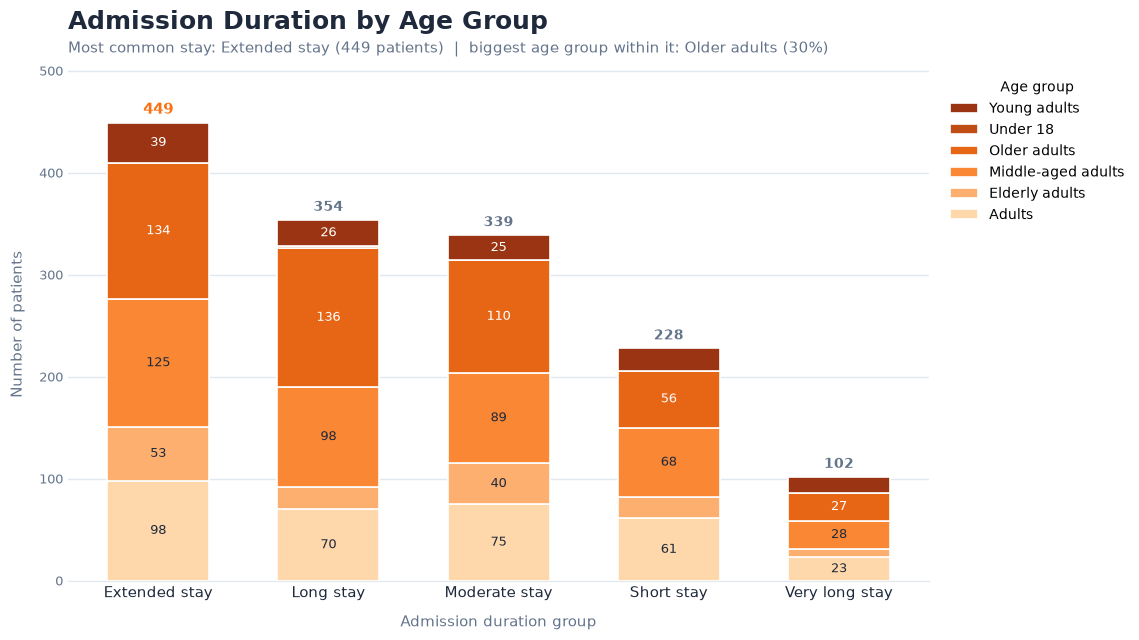

In [110]:


# --- Palette (same as the other charts) ---
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

MODE = "stacked"   # "stacked" or "grouped"

# ---------------- Prep ----------------
pv = age_ad_duration_pivot.set_index("admission_group").fillna(0)
pv.index   = pv.index.astype(str)
pv.columns = pv.columns.astype(str)

def num_order(labels):
    """Sort labels by the first number in each (e.g. '0-17', '18-34', '65+'); keep order if none."""
    found = [re.search(r"\d+", s) for s in labels]
    if all(found):
        return [s for _, s in sorted(zip([int(m.group()) for m in found], labels))]
    return list(labels)

pv = pv.loc[num_order(pv.index), num_order(pv.columns)]

groups, ages = pv.index.tolist(), pv.columns.tolist()
n, m = len(groups), len(ages)
totals = pv.sum(axis=1)

# Light-to-dark orange ramp, one shade per age group
cmap   = LinearSegmentedColormap.from_list("ora", ["#FED7AA", PEAK, "#9A3412"])
shades = [cmap(i / (m - 1)) if m > 1 else PEAK for i in range(m)]
dark   = [(i / (m - 1) if m > 1 else 1) > 0.45 for i in range(m)]   # white text on dark shades

top_group = totals.idxmax()
top_age   = pv.loc[top_group].idxmax()
top_share = pv.loc[top_group, top_age] / totals[top_group] * 100

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(max(11, n * 1.7 + 3), 6.5))
fig.patch.set_facecolor("white")
x = np.arange(n)

if MODE == "stacked":
    bottom = np.zeros(n)
    for k, a in enumerate(ages):
        vals = pv[a].values
        ax.bar(x, vals, bottom=bottom, width=0.6, color=shades[k],
               edgecolor="white", linewidth=1.2, label=a, zorder=3)
        for xi, v, b in zip(x, vals, bottom):
            if v >= totals.max() * 0.05:          # label only segments big enough to fit
                ax.text(xi, b + v / 2, f"{v:,.0f}", ha="center", va="center",
                        fontsize=9, color="white" if dark[k] else TEXT, zorder=4)
        bottom += vals
    for xi, g, t in zip(x, groups, totals):       # total on top of each column
        top = g == top_group
        ax.text(xi, t + totals.max() * 0.012, f"{t:,.0f}", ha="center", va="bottom",
                fontsize=11 if top else 10, fontweight="bold",
                color=PEAK if top else MUTED)
    ax.set_ylim(0, totals.max() * 1.12)
else:
    w = 0.8 / m
    for k, a in enumerate(ages):
        offs = (k - (m - 1) / 2) * w
        bars = ax.bar(x + offs, pv[a], width=w * 0.92, color=shades[k], label=a, zorder=3)
        ax.bar_label(bars, labels=[f"{v:,.0f}" for v in pv[a]], padding=3,
                     fontsize=8, color=MUTED)
    ax.set_ylim(0, pv.values.max() * 1.15)

# Titles
ax.set_title("Admission Duration by Age Group", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Most common stay: {top_group} ({totals[top_group]:,.0f} patients)  |  "
        f"biggest age group within it: {top_age} ({top_share:.0f}%)",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xticks(x)
ax.set_xticklabels(groups, fontsize=11, color=TEXT)
ax.set_xlabel("Admission duration group", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Number of patients", fontsize=11, color=MUTED, labelpad=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.tick_params(axis="x", length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)

# Legend outside the plot (reversed for stacked so it matches the stack order)
h, l = ax.get_legend_handles_labels()
if MODE == "stacked":
    h, l = h[::-1], l[::-1]
ax.legend(h, l, title="Age group", title_fontsize=10, fontsize=10, frameon=False,
          loc="upper left", bbox_to_anchor=(1.01, 1))

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/admission_duration_by_age_group.png", dpi=180)
plt.show()

In [111]:
gender = df.groupby(["pt_sex","admission_group"]).agg(
    count = ("pt_id","count")
).reset_index().sort_values("count",ascending=False).round(2)
gender 

,pt_sex,admission_group,count
5,m,Extended stay,235
0,f,Extended stay,216
6,m,Long stay,180
1,f,Long stay,175
7,m,Moderate stay,172
2,f,Moderate stay,167
8,m,Short stay,115
3,f,Short stay,115
9,m,Very long stay,53
4,f,Very long stay,49


In [112]:
gender_pivot = gender.pivot(index="admission_group",columns="pt_sex",values="count").reset_index()
gender_pivot

pt_sex,admission_group,f,m
0,Extended stay,216,235
1,Long stay,175,180
2,Moderate stay,167,172
3,Short stay,115,115
4,Very long stay,49,53


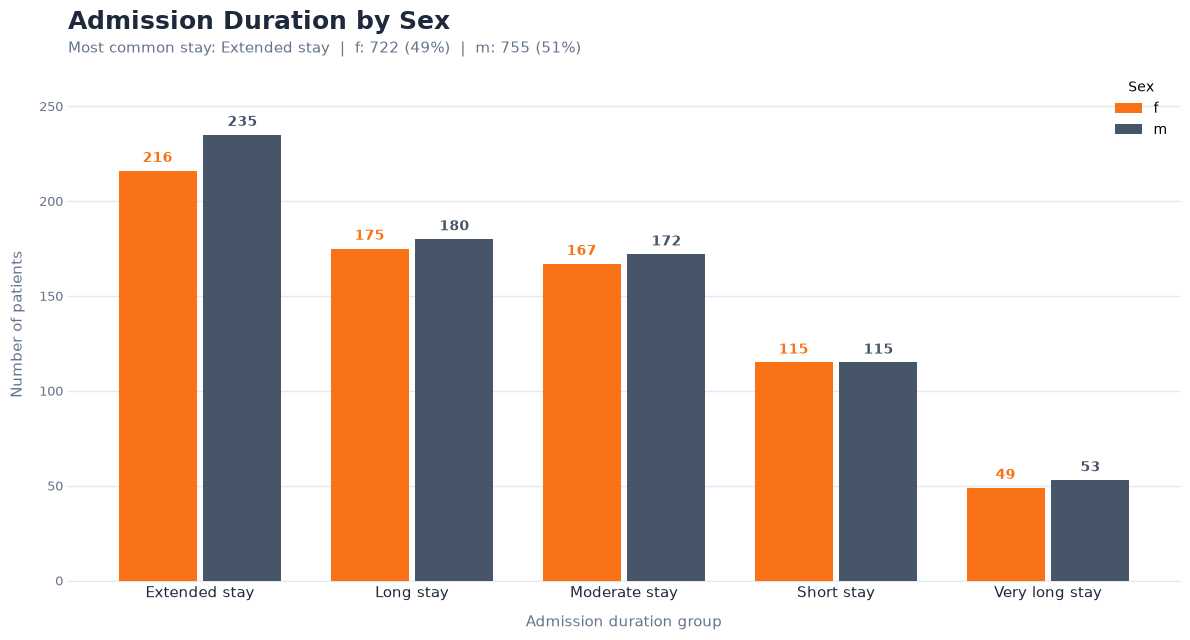

In [113]:
# --- Palette (same as the other charts) ---
PEAK  = "#F97316"
SLATE = "#475569"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"
SERIES = [PEAK, SLATE, "#CBD5E1", "#94A3B8"]   # one color per sex value

# ---------------- Prep ----------------
d = gender.copy()
d["pt_sex"]          = d["pt_sex"].astype(str)
d["admission_group"] = d["admission_group"].astype(str)

pv = d.pivot_table(index="admission_group", columns="pt_sex", values="count",
                   aggfunc="sum", fill_value=0)

def num_order(labels):
    """Sort labels by the first number in each (e.g. '1-3 days', '4-7 days'); keep order if none."""
    found = [re.search(r"\d+", s) for s in labels]
    if all(found):
        return [s for _, s in sorted(zip([int(m.group()) for m in found], labels))]
    return list(labels)

pv = pv.loc[num_order(pv.index)]

groups, sexes = pv.index.tolist(), pv.columns.tolist()
n, m = len(groups), len(sexes)
colors = {s: SERIES[i % len(SERIES)] for i, s in enumerate(sexes)}

total      = pv.values.sum()
sex_totals = pv.sum()
top_group  = pv.sum(axis=1).idxmax()

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(max(10, n * 1.8 + 3), 6.5))
fig.patch.set_facecolor("white")

x = np.arange(n)
w = 0.8 / m
for k, s in enumerate(sexes):
    offs = (k - (m - 1) / 2) * w
    bars = ax.bar(x + offs, pv[s], width=w * 0.92, color=colors[s], label=s, zorder=3)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in pv[s]], padding=4,
                 fontsize=10, color=colors[s] if colors[s] in (PEAK, SLATE) else MUTED,
                 fontweight="bold")

# Titles
split = "  |  ".join(f"{s}: {sex_totals[s]:,.0f} ({sex_totals[s] / total * 100:.0f}%)"
                     for s in sexes)
ax.set_title("Admission Duration by Sex", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Most common stay: {top_group}  |  {split}",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xticks(x)
ax.set_xticklabels(groups, fontsize=11, color=TEXT)
ax.set_xlabel("Admission duration group", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Number of patients", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylim(0, pv.values.max() * 1.15)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.tick_params(axis="x", length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
ax.legend(frameon=False, loc="upper right", fontsize=10, title="Sex", title_fontsize=10)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/admission_duration_by_sex.png", dpi=180)
plt.show()

In [114]:
# mortality rate gender 
mortalitly_gender = df[df["dead"] == "yes"].groupby(["pt_sex","dead"]).agg(
    count = ("pt_id","count")
).reset_index().sort_values("count",ascending=False).round(2)
mortalitly_gender 

,pt_sex,dead,count
1,m,yes,149
0,f,yes,141


In [115]:
occupation = df.groupby(["pt_occupation","admission_group"]).agg(
    count = ("pt_id","count")
).reset_index().sort_values("count",ascending=False)
occupation

,pt_occupation,admission_group,count
152,trading,Extended stay,128
153,trading,Long stay,119
154,trading,Moderate stay,92
116,retiree,Extended stay,69
155,trading,Short stay,57
...,...,...,...
140,stylist,Short stay,1
141,surveyor,Extended stay,1
139,stylist,Long stay,1
158,transporter,Moderate stay,1


In [116]:
diseases = ["ckd", "pud", "stroke","dm" ,"cancer"]

for disease in diseases:
    disease = df[df[disease] == "yes"].groupby(["age_group",disease]).agg(
        count = ("pt_id","count")
    ).reset_index().sort_values("count",ascending=False)
    disease["pct"] = ( disease["count"] / disease["count"].sum() * 100).round(2)
    print(disease)
    print()

            age_group  ckd  count    pct
2  Middle-aged adults  yes    108  33.44
3        Older adults  yes     89  27.55
0              Adults  yes     80  24.77
4        Young adults  yes     32   9.91
1      Elderly adults  yes     14   4.33

            age_group  pud  count    pct
3        Older adults  yes     59  35.12
0              Adults  yes     42  25.00
2  Middle-aged adults  yes     35  20.83
1      Elderly adults  yes     26  15.48
4        Young adults  yes      6   3.57

            age_group stroke  count    pct
2  Middle-aged adults    yes    143  41.45
3        Older adults    yes    113  32.75
0              Adults    yes     49  14.20
1      Elderly adults    yes     33   9.57
4        Young adults    yes      7   2.03

            age_group   dm  count    pct
2  Middle-aged adults  yes     52  31.33
3        Older adults  yes     52  31.33
0              Adults  yes     32  19.28
4        Young adults  yes     18  10.84
1      Elderly adults  yes     12   7.23



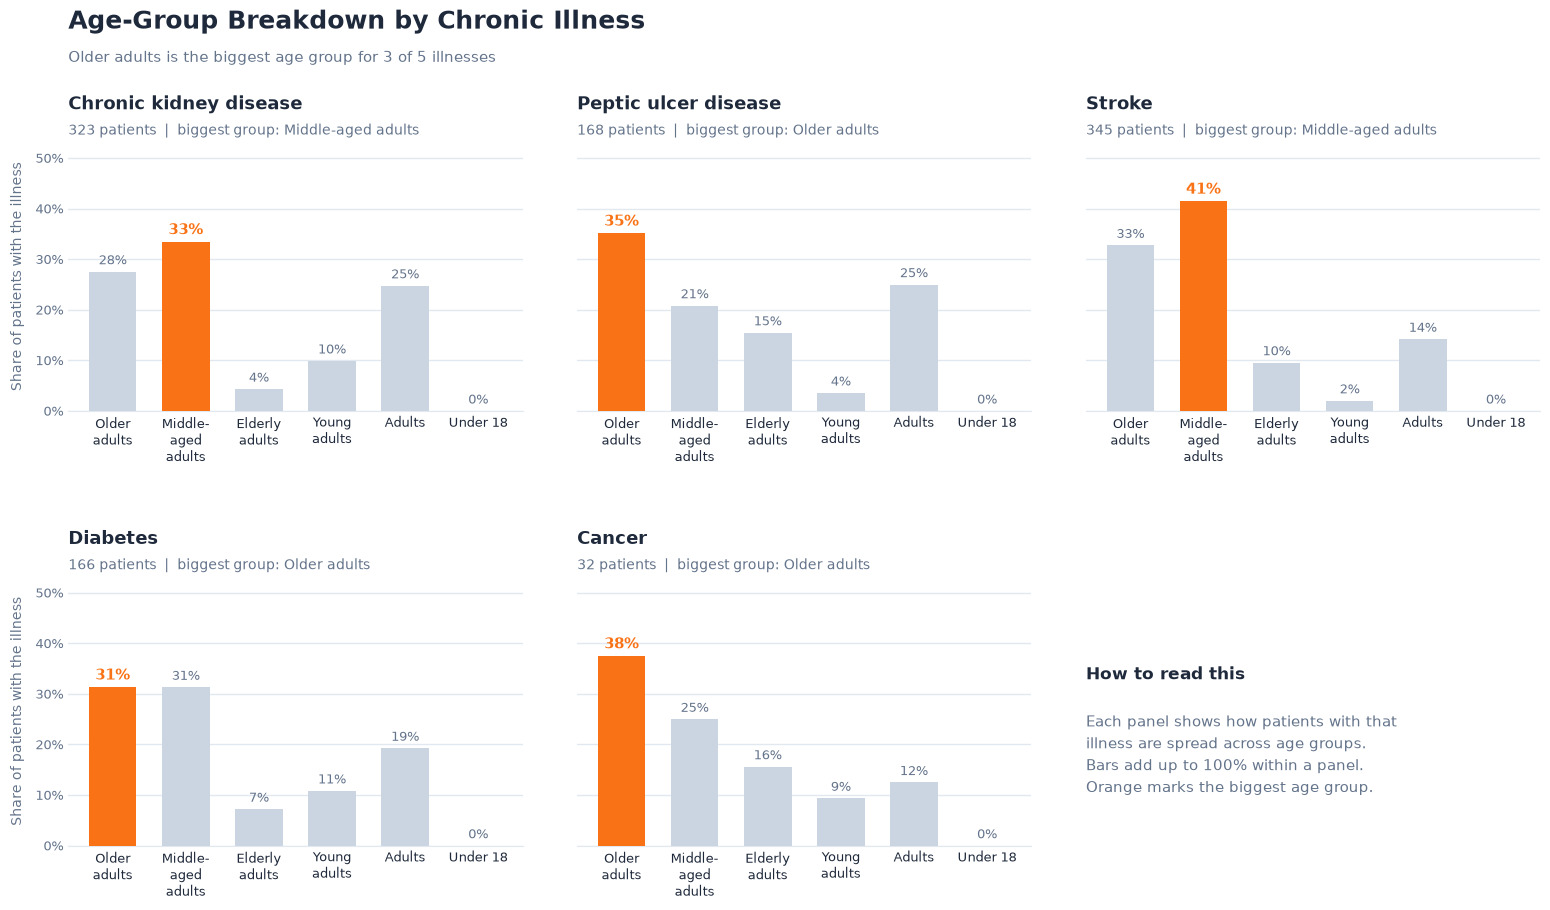

In [ ]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

diseases = ["ckd", "pud", "stroke", "dm", "cancer"]   # same list as your loop
NAMES = {
    "ckd": "Chronic kidney disease",
    "pud": "Peptic ulcer disease",
    "stroke": "Stroke",
    "dm": "Diabetes",
    "cancer": "Cancer",
}
YES = ["yes", "1", "true"]

# Optional: set your own age order, e.g. ["0-17", "18-34", "35-49", "50-64", "65+"]
AGE_ORDER = None

# ---------------- Prep ----------------
ages = [str(a) for a in df["age_group"].dropna().unique()]
if AGE_ORDER:
    ages = [a for a in AGE_ORDER if a in ages]
else:
    found = [re.search(r"\d+", a) for a in ages]
    if all(found):   # sort youngest to oldest by the first number in each label
        ages = [a for _, a in sorted(zip([int(m.group()) for m in found], ages))]

counts, pcts, tops, ns = {}, {}, {}, {}
for ill in diseases:
    has = df[ill].astype(str).str.strip().str.lower().isin(YES)
    c = df.loc[has, "age_group"].astype(str).value_counts().reindex(ages, fill_value=0)
    counts[ill], ns[ill] = c, int(c.sum())
    pcts[ill] = c / c.sum() * 100 if c.sum() else c * 0.0
    tops[ill] = pcts[ill].idxmax()

ymax = max(p.max() for p in pcts.values()) * 1.28
common_age, common_n = Counter(tops.values()).most_common(1)[0]

# ---------------- Plot ----------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5), sharey=True)
fig.patch.set_facecolor("white")
fig.subplots_adjust(left=0.06, right=0.98, top=0.82, bottom=0.08, hspace=0.62, wspace=0.12)
axes = axes.flatten()

x = np.arange(len(ages))
labels = [textwrap.fill(a, 10) for a in ages]

for ax, ill in zip(axes, diseases):
    p, c = pcts[ill], counts[ill]
    hi = int(p.values.argmax())
    colors = [PEAK if i == hi else BASE for i in range(len(ages))]
    bars = ax.bar(x, p.values, color=colors, width=0.65, zorder=3)

    t = ax.bar_label(bars, labels=[f"{v:.0f}%" for v in p.values], padding=3,
                     fontsize=9.5, color=MUTED)
    t[hi].set_color(PEAK)
    t[hi].set_fontweight("bold")
    t[hi].set_fontsize(10.5)

    ax.set_title(NAMES.get(ill, ill.upper()), loc="left", fontsize=13,
                 fontweight="bold", color=TEXT, pad=24)
    ax.text(0, 1.03, f"{ns[ill]:,} patients  |  biggest group: {tops[ill]}",
            transform=ax.transAxes, fontsize=10, color=MUTED)

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=9, color=TEXT,
                       rotation=0 if len(ages) <= 6 else 40,
                       ha="center" if len(ages) <= 6 else "right")
    ax.set_ylim(0, ymax)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.tick_params(axis="x", length=0)
    ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

# Unused 6th panel: how to read the chart
axes[5].axis("off")
axes[5].text(0, 0.62, "How to read this", transform=axes[5].transAxes,
             fontsize=12, fontweight="bold", color=TEXT)
axes[5].text(0, 0.5, "Each panel shows how patients with that\nillness are spread across age groups.\n"
             "Bars add up to 100% within a panel.\nOrange marks the biggest age group.",
             transform=axes[5].transAxes, fontsize=10.5, color=MUTED, va="top", linespacing=1.5)

for r in (0, 1):
    axes[r * 3].set_ylabel("Share of patients with the illness", fontsize=10,
                           color=MUTED, labelpad=8)

# Titles
fig.text(0.06, 0.94, "Age-Group Breakdown by Chronic Illness", fontsize=18,
         fontweight="bold", color=TEXT)
fig.text(0.06, 0.905,
         f"{common_age} is the biggest age group for {common_n} of {len(diseases)} illnesses",
         fontsize=11, color=MUTED)


plt.savefig("../images/age_group_by_illness.png", dpi=180, facecolor="white")
plt.show()

In [118]:
# mortality_disease =
for disease in diseases:
    disease = df[df[disease] == "yes"].groupby([disease,"dead"]).agg(
        count = ("pt_id","count")
    ).reset_index()
    disease["death_pct"] = (disease["count"]/disease["count"].sum() * 100).round(2)
    print(disease)
    print()

   ckd dead  count  death_pct
0  yes   no    250      77.16
1  yes  yes     74      22.84

   pud dead  count  death_pct
0  yes   no    148       88.1
1  yes  yes     20       11.9

  stroke dead  count  death_pct
0    yes   no    271       78.1
1    yes  yes     76       21.9

    dm dead  count  death_pct
0  yes   no    115      69.28
1  yes  yes     51      30.72

  cancer dead  count  death_pct
0    yes   no     15      46.88
1    yes  yes     17      53.12



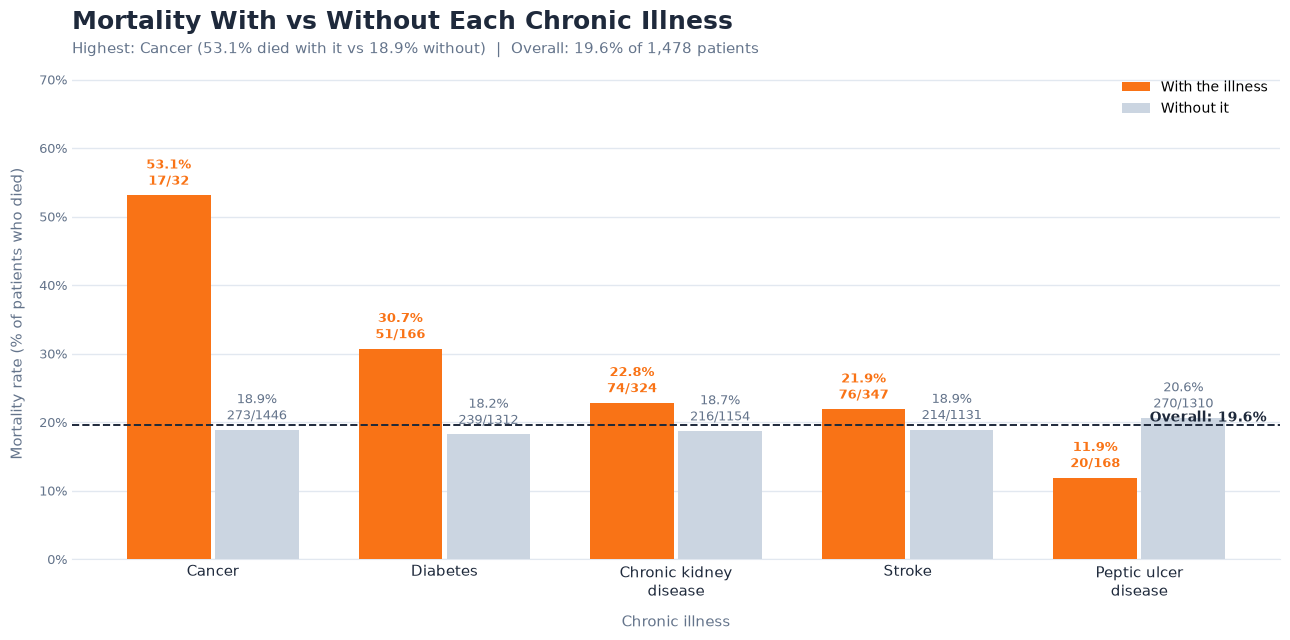

In [119]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

diseases = ["ckd", "dm", "stroke", "cancer", "pud"]   # same list as your loop
NAMES = {
    "ckd": "Chronic kidney disease",
    "dm": "Diabetes",
    "stroke": "Stroke",
    "cancer": "Cancer",
    "pud": "Peptic ulcer disease",
}
YES = ["yes", "1", "true"]

# ---------------- Prep ----------------
def is_yes(s):
    return s.astype(str).str.strip().str.lower().isin(YES)

dead    = is_yes(df["dead"])
overall = dead.mean() * 100

rows = []
for ill in diseases:
    has = is_yes(df[ill])
    r = {"illness": ill}
    for key, grp in [("with", has), ("without", ~has)]:
        n, d = int(grp.sum()), int(dead[grp].sum())
        r[f"{key}_n"], r[f"{key}_dead"] = n, d
        r[f"{key}_rate"] = d / n * 100 if n else 0
    rows.append(r)

mort = (pd.DataFrame(rows)
        .sort_values("with_rate", ascending=False).reset_index(drop=True))

labels = [NAMES.get(i, i.upper()) for i in mort["illness"]]
labels = [textwrap.fill(l, 14) for l in labels]

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(max(10, len(mort) * 2.2 + 2), 6.5))
fig.patch.set_facecolor("white")

x = np.arange(len(mort))
w = 0.38
b1 = ax.bar(x - w / 2, mort["with_rate"], width=w * 0.95, color=PEAK,
            label="With the illness", zorder=3)
b2 = ax.bar(x + w / 2, mort["without_rate"], width=w * 0.95, color=BASE,
            label="Without it", zorder=3)

t1 = ax.bar_label(b1, labels=[f"{r:.1f}%\n{d}/{n}" for r, d, n in
                              zip(mort["with_rate"], mort["with_dead"], mort["with_n"])],
                  padding=4, fontsize=9.5, color=PEAK, fontweight="bold", linespacing=1.3)
t2 = ax.bar_label(b2, labels=[f"{r:.1f}%\n{d}/{n}" for r, d, n in
                              zip(mort["without_rate"], mort["without_dead"], mort["without_n"])],
                  padding=4, fontsize=9.5, color=MUTED, linespacing=1.3)

# Overall death rate reference line
ax.axhline(overall, color=TEXT, linestyle="--", linewidth=1.4, zorder=4)
ax.text(len(mort) - 0.45, overall, f"Overall: {overall:.1f}%", ha="right", va="bottom",
        fontsize=10, color=TEXT, fontweight="bold")

# Titles
top = mort.iloc[0]
top_name = NAMES.get(top["illness"], top["illness"].upper())
ax.set_title("Mortality With vs Without Each Chronic Illness", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Highest: {top_name} ({top['with_rate']:.1f}% died with it vs "
        f"{top['without_rate']:.1f}% without)  |  Overall: {overall:.1f}% of {len(df):,} patients",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11, color=TEXT)
ax.set_xlabel("Chronic illness", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Mortality rate (% of patients who died)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylim(0, max(mort["with_rate"].max(), mort["without_rate"].max()) * 1.35)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.tick_params(axis="x", length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
ax.legend(frameon=False, loc="upper right", fontsize=10)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/mortality_by_illness.png", dpi=180)
plt.show()

In [120]:
age_group_dead = df[df["dead"] == "yes"].groupby(["age_group","dead"]).agg(
    count = ("pt_id","count")
).reset_index().sort_values("count",ascending=False)
age_group_dead["pct"] = ( age_group_dead["count"] / age_group_dead["count"].sum() * 100).round(2)
age_group_dead

,age_group,dead,count,pct
3,Older adults,yes,88,30.45
2,Middle-aged adults,yes,81,28.03
0,Adults,yes,58,20.07
1,Elderly adults,yes,46,15.92
4,Young adults,yes,16,5.54


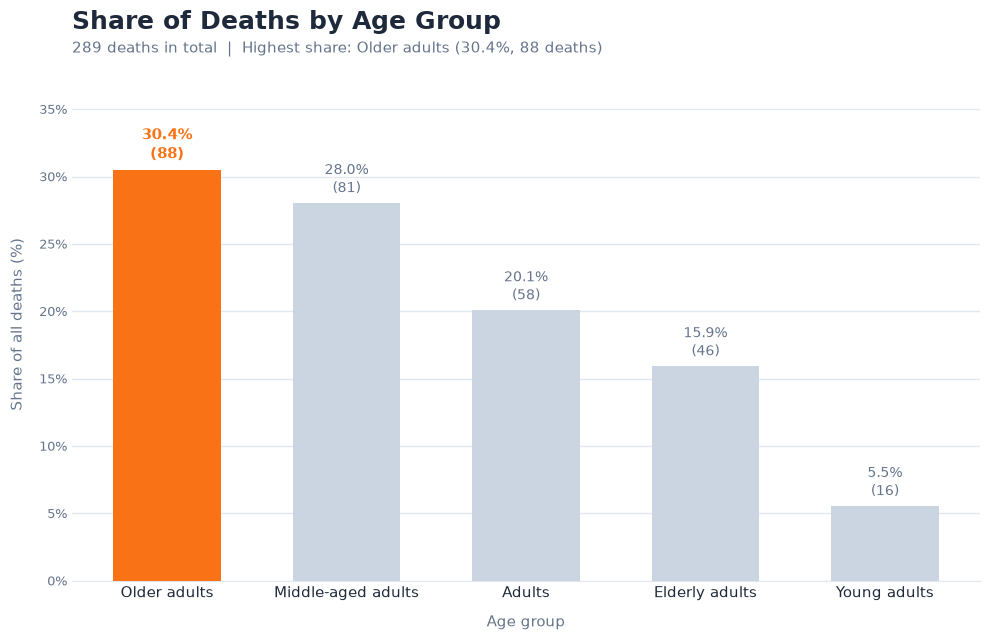

In [121]:


# --- Palette  ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

# ---------------- Prep ----------------
data = age_group_dead.copy()
data["age_group"] = data["age_group"].astype(str)

# Natural age order (youngest to oldest) if the labels contain numbers, e.g. "0-17", "18-34", "65+"
nums = data["age_group"].str.extract(r"(\d+)")[0]
if nums.notna().all():
    data = data.assign(_k=nums.astype(int)).sort_values("_k").drop(columns="_k")
data = data.reset_index(drop=True)

groups = data["age_group"]
counts = data["count"]
pcts   = data["pct"]

hi = int(pcts.values.argmax())
total = counts.sum()

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(max(10, len(data) * 1.4), 6.5))
fig.patch.set_facecolor("white")

colors = [PEAK if i == hi else BASE for i in range(len(data))]
bars = ax.bar(groups, pcts, color=colors, width=0.6, zorder=3)

# Labels: share on top, count in brackets
t = ax.bar_label(bars, labels=[f"{p:.1f}%\n({n:,})" for p, n in zip(pcts, counts)],
                 padding=5, fontsize=10, color=MUTED, linespacing=1.3)
t[hi].set_color(PEAK)
t[hi].set_fontweight("bold")
t[hi].set_fontsize(11)

# Titles
ax.set_title("Share of Deaths by Age Group", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"{total:,} deaths in total  |  Highest share: {groups.iloc[hi]} "
        f"({pcts.iloc[hi]:.1f}%, {counts.iloc[hi]:,} deaths)",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Age group", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Share of all deaths (%)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylim(0, pcts.max() * 1.25)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.tick_params(axis="x", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()
plt.savefig("../images/deaths_by_age_group.png", dpi=180)
plt.show()

In [122]:
occupation_dead = df[df["dead"] == "yes"].groupby(["pt_occupation","dead"]).agg(
    count = ("pt_id","count")
).reset_index().sort_values("count",ascending=False)
occupation_dead["pct"] = ( occupation_dead["count"] / occupation_dead["count"].sum() * 100).round(2)
occupation_dead

,pt_occupation,dead,count,pct
34,trading,yes,85,29.31
26,retiree,yes,48,16.55
11,dependant,yes,26,8.97
35,unemployed,yes,25,8.62
10,computer scientist,yes,16,5.52
16,farming,yes,14,4.83
30,student,yes,13,4.48
9,clergy,yes,10,3.45
33,teaching,yes,7,2.41
12,driver,yes,6,2.07
